In [1]:
from pathlib import Path
import os
import random
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from ultralytics import YOLO

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)

## 1. Confirming CUDA is being used

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", GPU_NAME)
print("Device:", DEVICE)

PyTorch: 2.14.0+cu130
CUDA: 13.0
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Device: cuda


## 2. Reproducibility

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

## 3. Locating the AutoVision project root

In [4]:
def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate

    raise FileNotFoundError(
        "Could not find AutoVision project root containing pyproject.toml."
    )

PROJECT_ROOT = find_project_root()

REPORT_DIR = PROJECT_ROOT / "reports" / "damage_detection_benchmark"
MODEL_DIR = PROJECT_ROOT / "models" / "damage_detection_benchmark"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Report directory:", REPORT_DIR)
print("Model directory:", MODEL_DIR)

Project root: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development
Report directory: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\reports\damage_detection_benchmark
Model directory: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\damage_detection_benchmark


## 4. Locating the CarDD dataset

In [5]:
candidate_roots = [
    PROJECT_ROOT / "data" / "external" / "cardd_kaggle" / "extracted",
    PROJECT_ROOT / "data" / "raw" / "cardd_kaggle" / "extracted",

    Path(
        r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
        r"\capstone-vehicle-metadata\data\cardd_kaggle\extracted"
    ),

    Path(
        r"G:\My Drive\capstone-vehicle-metadata\data\cardd_kaggle\extracted"
    ),
]

DATASET_ROOT = next(
    (
        p for p in candidate_roots
        if (p / "train" / "images").exists()
        and (p / "train" / "labels").exists()
    ),
    None,
)

print("DATASET_ROOT:", DATASET_ROOT)

if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the prepared CarDD dataset. "
        "Set DATASET_ROOT manually to the folder containing train/val/test."
    )

DATASET_ROOT: G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\capstone-vehicle-metadata\data\cardd_kaggle\extracted


## 5. Validating image-label counts and class distribution

In [6]:
CLASS_NAMES = [
    "dent",
    "scratch",
    "crack",
    "glass shatter",
    "lamp broken",
    "tire flat",
]

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
}

summary_rows = []
class_instance_counts = {
    name: 0
    for name in CLASS_NAMES
}

for split in ["train", "val", "test"]:
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    image_files = sorted(
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    )

    label_files = sorted(
        label_dir.glob("*.txt")
    )

    images_without_labels = 0
    total_instances = 0

    for image_path in image_files:
        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            images_without_labels += 1
            continue

        for line in label_path.read_text(
            encoding="utf-8",
            errors="ignore",
        ).splitlines():
            parts = line.strip().split()

            if len(parts) < 5:
                continue

            class_id = int(parts[0])

            if 0 <= class_id < len(CLASS_NAMES):
                class_instance_counts[
                    CLASS_NAMES[class_id]
                ] += 1

            total_instances += 1

    summary_rows.append({
        "split": split,
        "images": len(image_files),
        "label_files": len(label_files),
        "images_without_label_file": images_without_labels,
        "damage_instances": total_instances,
    })

summary_df = pd.DataFrame(summary_rows)

display(summary_df)

class_counts_df = (
    pd.DataFrame(
        class_instance_counts.items(),
        columns=["damage_class", "instances"],
    )
    .sort_values(
        "instances",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(class_counts_df)

summary_df.to_csv(
    REPORT_DIR / "cardd_dataset_summary.csv",
    index=False,
)

class_counts_df.to_csv(
    REPORT_DIR / "cardd_class_instance_counts.csv",
    index=False,
)

,split,images,label_files,images_without_label_file,damage_instances
0,train,2816,2816,0,6211
1,val,810,810,0,1744
2,test,374,374,0,785


,damage_class,instances
0,scratch,3595
1,dent,2543
2,crack,898
3,lamp broken,704
4,glass shatter,681
5,tire flat,319


## 6. Creating a local Ultralytics dataset YAML

In [7]:
LOCAL_YAML = INTERIM_DIR / "cardd_damage_local.yaml"

yaml_lines = [
    f'path: "{DATASET_ROOT.as_posix()}"',
    "train: train/images",
    "val: val/images",
    "test: test/images",
    "names:",
]

for class_id, class_name in enumerate(CLASS_NAMES):
    yaml_lines.append(
        f"  {class_id}: {class_name}"
    )

LOCAL_YAML.write_text(
    "\n".join(yaml_lines) + "\n",
    encoding="utf-8",
)

print(LOCAL_YAML.read_text())
print("Saved:", LOCAL_YAML)

path: "G:/.shortcut-targets-by-id/1OOvt005TduvEA8h6_snfuyQtbQAjo-3J/capstone-vehicle-metadata/data/cardd_kaggle/extracted"
train: train/images
val: val/images
test: test/images
names:
  0: dent
  1: scratch
  2: crack
  3: glass shatter
  4: lamp broken
  5: tire flat

Saved: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\data\interim\cardd_damage_local.yaml


## 7. Training configuration

In [8]:
IMGSZ = 640
BATCH_SIZE = 8
EPOCHS = 30
PATIENCE = 7
WORKERS = 0
DEVICE_ID = 0 if torch.cuda.is_available() else "cpu"

MODEL_NAMES = [
    "yolo11n",
    "yolo11s",
]

TRAINING_CONFIG = {
    "imgsz": IMGSZ,
    "batch": BATCH_SIZE,
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "workers": WORKERS,
    "device": DEVICE_ID,
    "seed": SEED,
    "deterministic": True,
    "amp": True,
    "cache": False,
}

print(TRAINING_CONFIG)

{'imgsz': 640, 'batch': 8, 'epochs': 30, 'patience': 7, 'workers': 0, 'device': 0, 'seed': 42, 'deterministic': True, 'amp': True, 'cache': False}


## 8. Locating pretrained YOLO weights

In [9]:
def resolve_pretrained_weight(model_name):
    filename = f"{model_name}.pt"

    candidates = [
        PROJECT_ROOT / "notebooks" / filename,
        PROJECT_ROOT / "models" / filename,
        PROJECT_ROOT / filename,
    ]

    for path in candidates:
        if path.exists():
            return str(path)

    return filename


for model_name in MODEL_NAMES:
    print(
        model_name,
        "->",
        resolve_pretrained_weight(model_name),
    )

yolo11n -> C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\notebooks\yolo11n.pt
yolo11s -> C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\notebooks\yolo11s.pt


## 9. Metric extraction helper

In [10]:
def safe_float(value):
    if value is None:
        return np.nan

    try:
        return float(value)
    except Exception:
        return np.nan


def extract_detection_metrics(metrics):
    box = metrics.box

    return {
        "precision": safe_float(
            getattr(box, "mp", None)
        ),
        "recall": safe_float(
            getattr(box, "mr", None)
        ),
        "map50": safe_float(
            getattr(box, "map50", None)
        ),
        "map50_95": safe_float(
            getattr(box, "map", None)
        ),
        "inference_ms_per_image": safe_float(
            getattr(metrics, "speed", {}).get(
                "inference",
                np.nan,
            )
        ),
    }


def per_class_metrics_dataframe(
    metrics,
    model,
    split,
    model_name,
):
    box = metrics.box

    ap50 = np.asarray(
        getattr(box, "ap50", [])
    )

    ap50_95 = np.asarray(
        getattr(box, "maps", [])
    )

    precision = np.asarray(
        getattr(box, "p", [])
    )

    recall = np.asarray(
        getattr(box, "r", [])
    )

    n = len(CLASS_NAMES)

    def value_at(array, i):
        return (
            float(array[i])
            if i < len(array)
            else np.nan
        )

    rows = []

    for i in range(n):
        rows.append({
            "model": model_name,
            "split": split,
            "class_id": i,
            "damage_class": model.names.get(
                i,
                CLASS_NAMES[i],
            ),
            "precision": value_at(
                precision,
                i,
            ),
            "recall": value_at(
                recall,
                i,
            ),
            "ap50": value_at(
                ap50,
                i,
            ),
            "ap50_95": value_at(
                ap50_95,
                i,
            ),
        })

    return pd.DataFrame(rows)

## 10. Training YOLO11n and YOLO11s

In [11]:
all_results = []
all_per_class = []
best_checkpoint_paths = {}

for model_name in MODEL_NAMES:
    print("\n" + "=" * 90)
    print("DAMAGE DETECTION |", model_name)
    print("=" * 90)

    pretrained_weight = resolve_pretrained_weight(
        model_name
    )

    model = YOLO(
        pretrained_weight
    )

    run_name = (
        f"{model_name}_cardd_"
        f"{IMGSZ}px"
    )

    train_result = model.train(
        data=str(LOCAL_YAML),
        project=str(MODEL_DIR),
        name=run_name,
        exist_ok=True,
        imgsz=IMGSZ,
        batch=BATCH_SIZE,
        epochs=EPOCHS,
        patience=PATIENCE,
        workers=WORKERS,
        device=DEVICE_ID,
        seed=SEED,
        deterministic=True,
        amp=True,
        cache=False,
        pretrained=True,
        plots=True,
        verbose=True,
    )

    run_dir = Path(
        train_result.save_dir
    )

    best_checkpoint = (
        run_dir
        / "weights"
        / "best.pt"
    )

    if not best_checkpoint.exists():
        raise FileNotFoundError(
            f"Best checkpoint not found: {best_checkpoint}"
        )

    best_checkpoint_paths[
        model_name
    ] = best_checkpoint

    best_model = YOLO(
        str(best_checkpoint)
    )

    print("\nValidation evaluation")
    val_metrics = best_model.val(
        data=str(LOCAL_YAML),
        split="val",
        imgsz=IMGSZ,
        batch=BATCH_SIZE,
        workers=WORKERS,
        device=DEVICE_ID,
        plots=True,
        verbose=False,
    )

    print("\nTest evaluation")
    test_metrics = best_model.val(
        data=str(LOCAL_YAML),
        split="test",
        imgsz=IMGSZ,
        batch=BATCH_SIZE,
        workers=WORKERS,
        device=DEVICE_ID,
        plots=True,
        verbose=False,
    )

    val_summary = extract_detection_metrics(
        val_metrics
    )

    test_summary = extract_detection_metrics(
        test_metrics
    )

    row = {
        "model": model_name,
        "checkpoint": str(
            best_checkpoint
        ),
        "val_precision": val_summary[
            "precision"
        ],
        "val_recall": val_summary[
            "recall"
        ],
        "val_map50": val_summary[
            "map50"
        ],
        "val_map50_95": val_summary[
            "map50_95"
        ],
        "test_precision": test_summary[
            "precision"
        ],
        "test_recall": test_summary[
            "recall"
        ],
        "test_map50": test_summary[
            "map50"
        ],
        "test_map50_95": test_summary[
            "map50_95"
        ],
        "test_inference_ms_per_image": test_summary[
            "inference_ms_per_image"
        ],
    }

    all_results.append(
        row
    )

    all_per_class.append(
        per_class_metrics_dataframe(
            val_metrics,
            best_model,
            "val",
            model_name,
        )
    )

    all_per_class.append(
        per_class_metrics_dataframe(
            test_metrics,
            best_model,
            "test",
            model_name,
        )
    )

    print("\nRESULT")
    print(row)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


DAMAGE DETECTION | yolo11n
New https://pypi.org/project/ultralytics/8.4.172 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.11.4 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\data\interim\cardd_damage_local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4

## 11. Comparing validation and test metrics

In [12]:
results_df = pd.DataFrame(
    all_results
)

results_df = results_df.sort_values(
    [
        "val_map50_95",
        "val_map50",
    ],
    ascending=[
        False,
        False,
    ],
).reset_index(
    drop=True
)

display(results_df)

results_df.to_csv(
    REPORT_DIR
    / "cardd_yolo_damage_results.csv",
    index=False,
)

per_class_df = pd.concat(
    all_per_class,
    ignore_index=True,
)

per_class_df.to_csv(
    REPORT_DIR
    / "cardd_yolo_per_class_metrics.csv",
    index=False,
)

display(
    per_class_df[
        per_class_df["split"]
        == "test"
    ]
)

,model,checkpoint,val_precision,val_recall,val_map50,val_map50_95,test_precision,test_recall,test_map50,test_map50_95,test_inference_ms_per_image
0,yolo11s,C:\Users\elesh\Academics\UTS\36127InnovationLa...,0.732367,0.688579,0.717842,0.571597,0.679287,0.710736,0.722024,0.565008,5.299838
1,yolo11n,C:\Users\elesh\Academics\UTS\36127InnovationLa...,0.683750,0.680862,0.684349,0.546096,0.681489,0.659462,0.683389,0.536153,4.178811


,model,split,class_id,damage_class,precision,recall,ap50,ap50_95
6,yolo11n,test,0,dent,0.630939,0.533898,0.589081,0.333711
7,yolo11n,test,1,scratch,0.576580,0.521173,0.556322,0.319737
8,yolo11n,test,2,crack,0.436512,0.309925,0.247003,0.110804
9,yolo11n,test,3,glass shatter,0.875323,0.985915,0.977004,0.892044
10,yolo11n,test,4,lamp broken,0.742335,0.793361,0.840302,0.698019
11,yolo11n,test,5,tire flat,0.827243,0.812500,0.890622,0.862606
18,yolo11s,test,0,dent,0.576822,0.622881,0.602977,0.361515
19,yolo11s,test,1,scratch,0.571561,0.557003,0.611058,0.347224
20,yolo11s,test,2,crack,0.402709,0.414286,0.380729,0.181239
21,yolo11s,test,3,glass shatter,0.885739,0.985915,0.987484,0.915040


## 12. Selecting the damage detector by validation performance

In [13]:
selected = results_df.iloc[
    0
]

print("Selected detector:", selected["model"])
print(
    "Validation mAP50-95:",
    f"{selected['val_map50_95']:.4f}",
)
print(
    "Validation mAP50:",
    f"{selected['val_map50']:.4f}",
)
print(
    "Test mAP50-95:",
    f"{selected['test_map50_95']:.4f}",
)
print(
    "Test mAP50:",
    f"{selected['test_map50']:.4f}",
)
print(
    "Test precision:",
    f"{selected['test_precision']:.4f}",
)
print(
    "Test recall:",
    f"{selected['test_recall']:.4f}",
)

pd.DataFrame([
    selected
]).to_csv(
    REPORT_DIR
    / "selected_damage_detector.csv",
    index=False,
)

Selected detector: yolo11s
Validation mAP50-95: 0.5716
Validation mAP50: 0.7178
Test mAP50-95: 0.5650
Test mAP50: 0.7220
Test precision: 0.6793
Test recall: 0.7107


## 13. Comparing per-class test AP

model,yolo11n,yolo11s
damage_class,,
crack,0.110804,0.181239
dent,0.333711,0.361515
glass shatter,0.892044,0.915040
lamp broken,0.698019,0.730209
scratch,0.319737,0.347224
tire flat,0.862606,0.854821


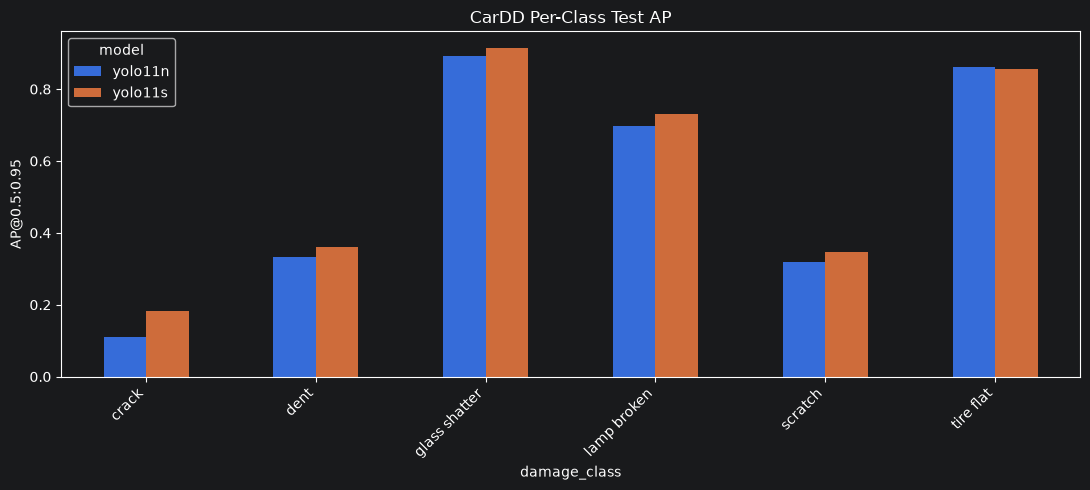

In [14]:
test_class_metrics = (
    per_class_df[
        per_class_df["split"]
        == "test"
    ]
    .copy()
)

pivot_map = (
    test_class_metrics
    .pivot(
        index="damage_class",
        columns="model",
        values="ap50_95",
    )
)

display(pivot_map)

pivot_map.plot(
    kind="bar",
    figsize=(11, 5),
)

plt.ylabel(
    "AP@0.5:0.95"
)

plt.title(
    "CarDD Per-Class Test AP"
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.tight_layout()
plt.show()

## 14. Test predictions

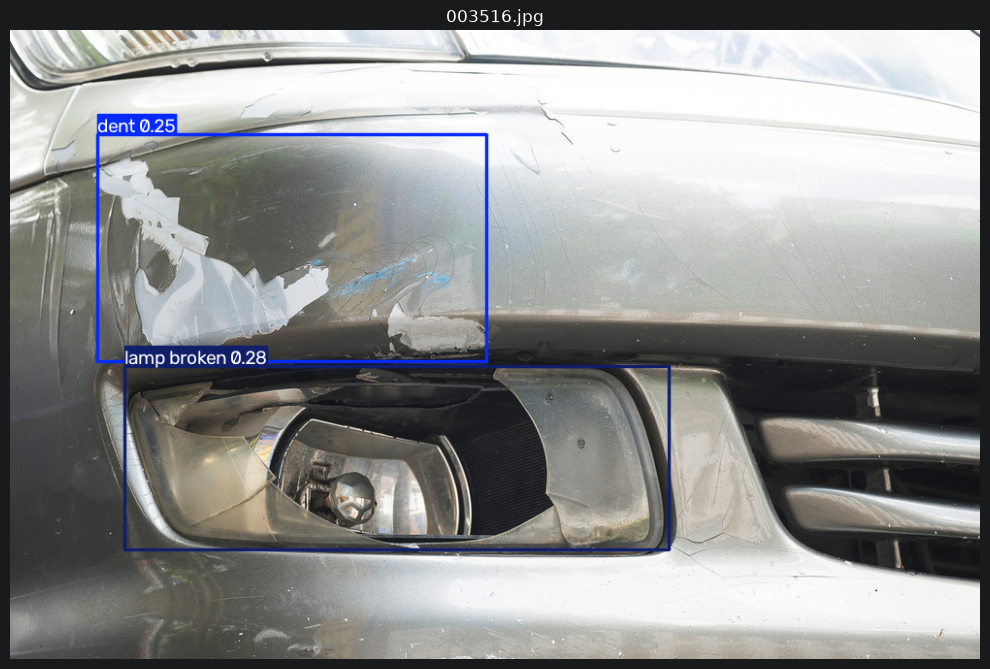

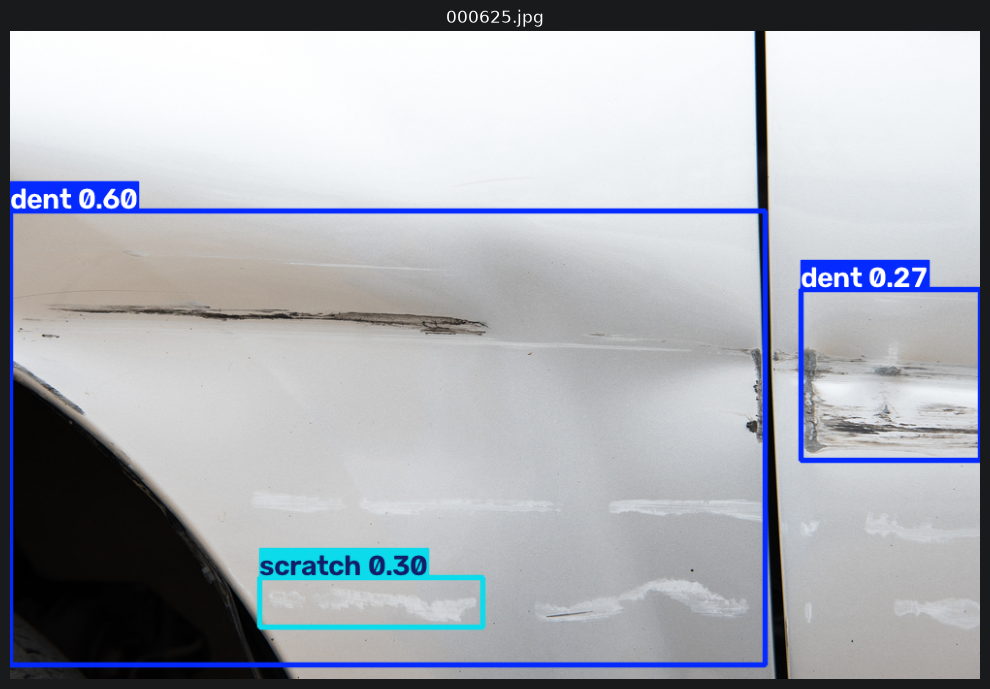

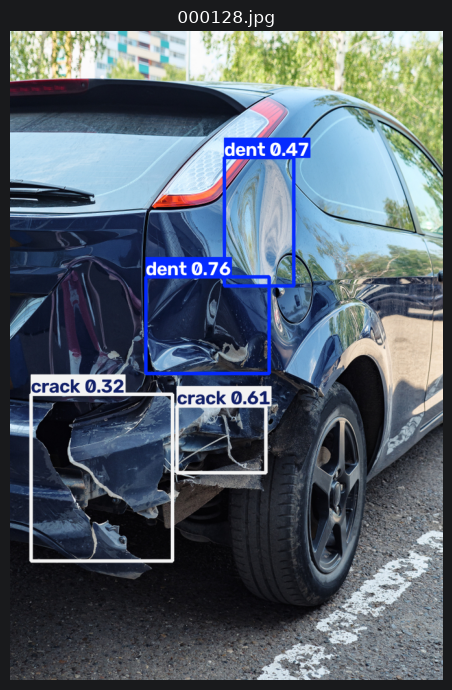

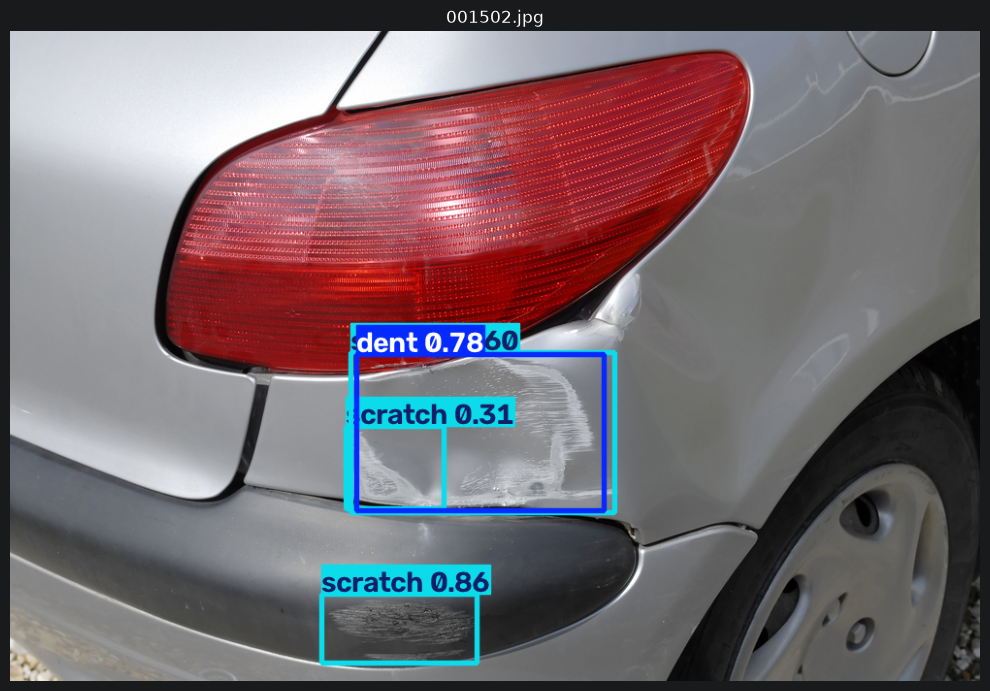

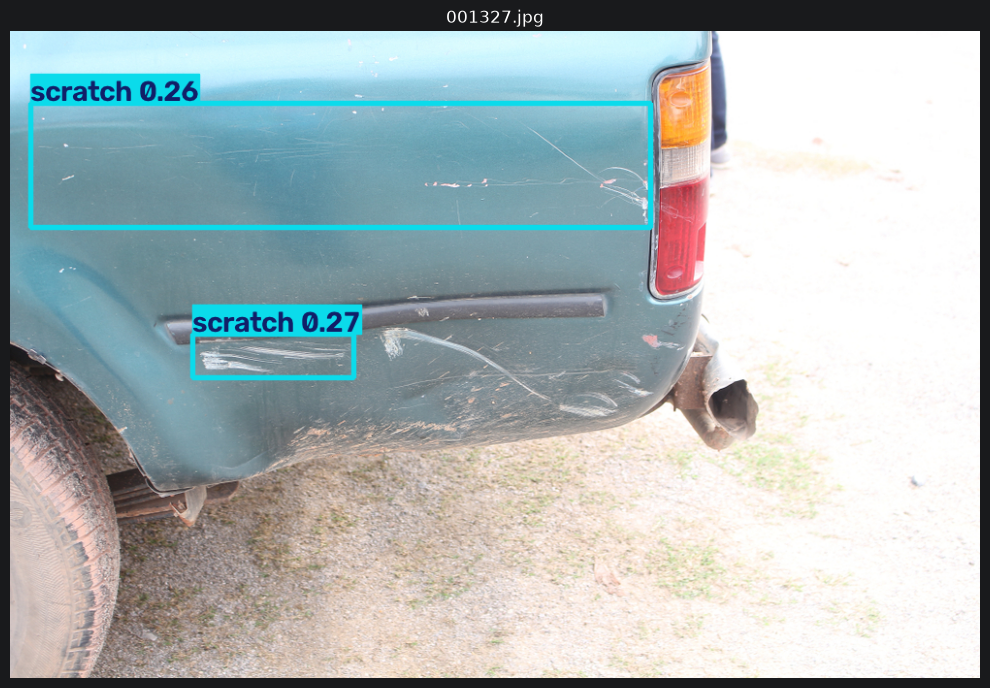

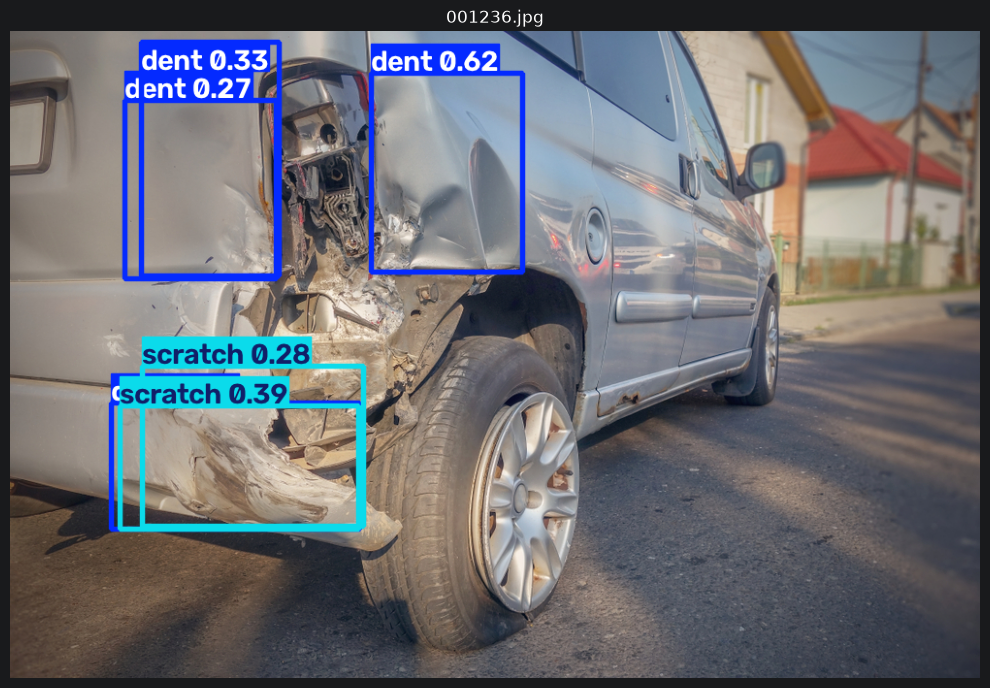

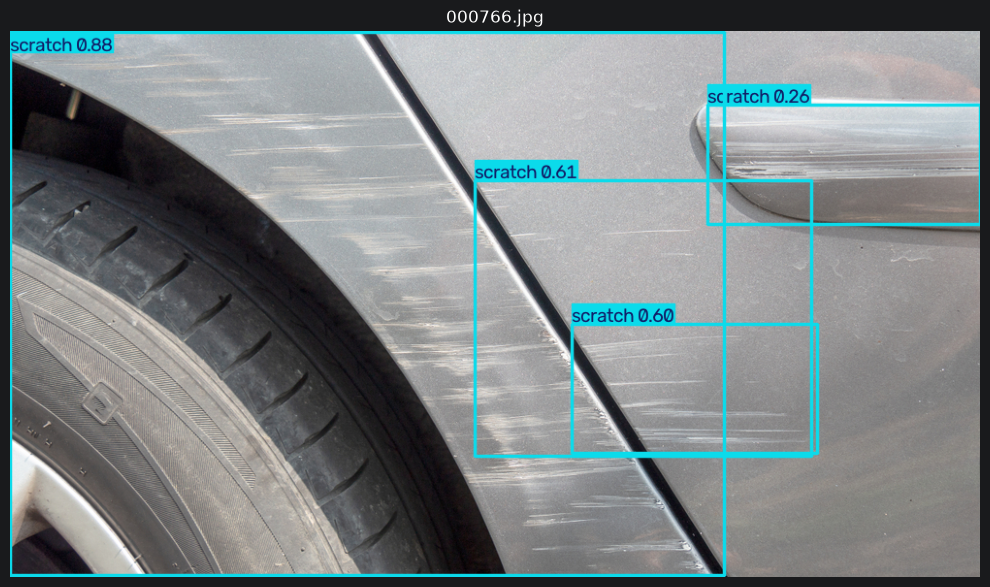

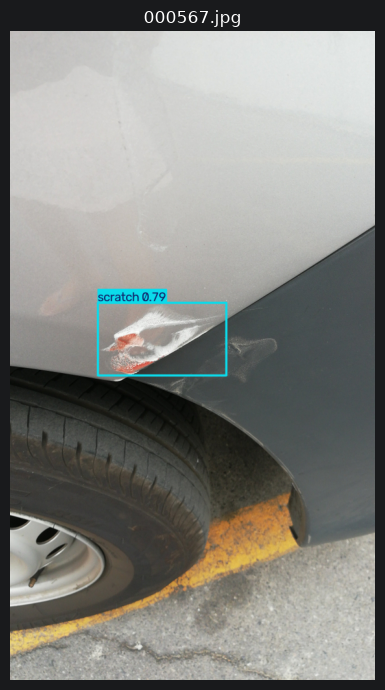

In [15]:
selected_model_name = str(
    selected["model"]
)

selected_model = YOLO(
    str(
        best_checkpoint_paths[
            selected_model_name
        ]
    )
)

test_image_dir = (
    DATASET_ROOT
    / "test"
    / "images"
)

test_images = sorted([
    p
    for p in test_image_dir.iterdir()
    if p.suffix.lower()
    in IMAGE_EXTENSIONS
])

rng = random.Random(
    SEED
)

sample_images = rng.sample(
    test_images,
    k=min(
        8,
        len(test_images),
    ),
)

predictions = selected_model.predict(
    source=[
        str(p)
        for p in sample_images
    ],
    imgsz=IMGSZ,
    conf=0.25,
    device=DEVICE_ID,
    verbose=False,
)

for image_path, result in zip(
    sample_images,
    predictions,
):
    plotted = result.plot()

    plotted_rgb = plotted[
        :,
        :,
        ::-1,
    ]

    plt.figure(
        figsize=(10, 7)
    )

    plt.imshow(
        plotted_rgb
    )

    plt.title(
        image_path.name
    )

    plt.axis(
        "off"
    )

    plt.tight_layout()
    plt.show()

## 14. AutoVision interpretation

Recommended reporting language after running the notebook:

> A damage-detection benchmark was conducted using the CarDD dataset and its official train, validation and test partitions. YOLO11n and YOLO11s were fine-tuned from pretrained weights at 640×640 resolution. Detector selection was based on validation mAP@0.5:0.95, while the official test split was reserved for final internal benchmark reporting. Precision, recall, mAP@0.5, mAP@0.5:0.95 and per-class AP were used to assess damage localisation performance.

### Important limitation

CarDD is strongly focused on damaged vehicles. In the prepared dataset, every image has at least one damage label.

For the final AutoVision application we should therefore later add a **negative/no-damage evaluation set** containing normal vehicles to answer:

> Does the model incorrectly detect damage when the vehicle is actually undamaged?

That is separate from measuring how well it detects labelled CarDD damage.